# Pertemuan 9: Machine Learning pada Big Data

## Capaian Pembelajaran Pertemuan (Sub-CPMK 3 - Kognitif K4, K5):
1. Menganalisis tantangan pelatihan model *Machine Learning* pada data besar: *Out-of-Memory (OOM)*, waktu training, dan biaya eksperimen.
2. Menerapkan strategi skalabilitas: *sampling* terarah, *downcasting* tipe data, dan *incremental learning* (`partial_fit`).
3. Melakukan *feature engineering* berkecepatan tinggi menggunakan **Polars Expressions** (fitur kalender, *lag*, *rolling*, agregasi).
4. Membangun **Scikit-learn Pipeline** + `ColumnTransformer` yang mencegah *data leakage*.
5. Membandingkan model ansambel pohon: **Random Forest** (*bagging*) vs **Histogram Gradient Boosting** (*boosting*).
6. Mengevaluasi model regresi dengan **MAE, RMSE, R²** menggunakan *time-based split* yang jujur.
7. Menginterpretasi model dengan **Feature Importance** (*impurity-based* vs *permutation importance*).
8. Menyiapkan check-in **Tugas 2 Phase 1** (team repo GitHub Classroom, dataset, desain arsitektur) dan menyiapkan *Final Submission* **Tugas 1**.

---
## Bagian 1: Inisialisasi Lingkungan & Import Library

In [1]:
import os
import time
import numpy as np
import polars as pl
import plotly.express as px
import plotly.graph_objects as go

import sklearn
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import SGDRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

sklearn.set_config(transform_output="default")

# LightGBM bersifat opsional (tersedia setelah image Docker di-rebuild)
try:
    import lightgbm as lgb
    LGBM_TERSEDIA = True
except ImportError:
    LGBM_TERSEDIA = False

print(f"Versi Polars       : {pl.__version__}")
print(f"Versi Scikit-learn : {sklearn.__version__}")
print(f"LightGBM tersedia  : {LGBM_TERSEDIA}")
print(f"Jumlah core CPU    : {os.cpu_count()}")

Versi Polars       : 2.1.0
Versi Scikit-learn : 1.9.1
LightGBM tersedia  : True
Jumlah core CPU    : 10


---
## Bagian 2: Dataset Sintetis Penjualan Harian E-Commerce (~1 Juta Baris)

**Kasus bisnis:** Sebuah marketplace ingin **memprediksi jumlah unit terjual per produk per hari** (*demand forecasting*) agar stok gudang tidak kosong maupun menumpuk.

Kita membangkitkan data **2.000 produk × 500 hari = 1.000.000 baris** dengan pola yang realistis:
- Musiman mingguan (akhir pekan lebih ramai) dan efek **tanggal kembar** (11.11, 12.12) serta **gajian** (tanggal 25–31).
- Efek **diskon** dan **harga** terhadap permintaan (elastisitas harga).
- Perbedaan popularitas antar produk, kategori, dan wilayah gudang.

Data disimpan dalam **Parquet (zstd)** di `data/processed/ml_demand/`.

In [2]:
output_dir = "data/processed/ml_demand"
os.makedirs(output_dir, exist_ok=True)
filepath_parquet = os.path.join(output_dir, "penjualan_harian.parquet")

N_PRODUK = 2_000
N_HARI = 500
rng = np.random.default_rng(2026)

if not os.path.exists(filepath_parquet):
    t0 = time.perf_counter()
    kategori = ["Elektronik", "Fashion", "Kecantikan", "Rumah Tangga", "Olahraga", "Makanan"]
    wilayah = ["Jabodetabek", "Jawa Barat", "Jawa Timur", "Sumatera", "Kalimantan", "Sulawesi"]

    # --- Atribut statis produk ---
    produk = pl.DataFrame({
        "produk_id": np.arange(N_PRODUK, dtype=np.int32),
        "kategori": rng.choice(kategori, N_PRODUK),
        "wilayah_gudang": rng.choice(wilayah, N_PRODUK, p=[0.35, 0.2, 0.2, 0.1, 0.08, 0.07]),
        "harga_dasar": np.round(rng.lognormal(mean=11.5, sigma=0.8, size=N_PRODUK), -2),
        "popularitas": rng.gamma(shape=2.0, scale=1.5, size=N_PRODUK),
        "rating_toko": np.round(rng.uniform(3.5, 5.0, N_PRODUK), 1),
    })

    # --- Grid produk x tanggal (cross join, dieksekusi di Rust) ---
    tanggal = pl.DataFrame({
        "tanggal": pl.date_range(pl.date(2025, 1, 1), pl.date(2025, 1, 1) + pl.duration(days=N_HARI - 1), "1d", eager=True)
    })
    df = produk.join(tanggal, how="cross")
    n = df.height

    diskon = np.where(rng.random(n) < 0.15, rng.choice([0.1, 0.2, 0.3, 0.5], n), 0.0)
    df = df.with_columns(
        pl.Series("diskon_persen", diskon),
        pl.Series("noise", rng.normal(0, 0.25, n)),
    )

    # --- Fungsi permintaan (log-linear) ---
    hari = pl.col("tanggal").dt.weekday()  # 1=Senin ... 7=Minggu
    tgl = pl.col("tanggal").dt.day()
    bln = pl.col("tanggal").dt.month()
    log_lambda = (
        pl.col("popularitas").log1p() * 1.2
        - 0.35 * (pl.col("harga_dasar") / 100_000).log1p()
        + 2.2 * pl.col("diskon_persen")
        + pl.when(hari >= 6).then(0.30).otherwise(0.0)
        + pl.when(tgl >= 25).then(0.20).otherwise(0.0)
        + pl.when(tgl == bln).then(0.90).otherwise(0.0)          # tanggal kembar
        + pl.when(pl.col("kategori") == "Fashion").then(0.25)
            .when(pl.col("kategori") == "Elektronik").then(-0.20).otherwise(0.0)
        + 0.15 * (pl.col("rating_toko") - 4.0)
        + 0.25 * (2 * np.pi * pl.col("tanggal").dt.ordinal_day() / 365).sin()
        + pl.col("noise")
    )
    df = df.with_columns(log_lambda.exp().alias("lam"))
    unit = rng.poisson(df["lam"].to_numpy())

    df = (
        df.with_columns(
            pl.Series("unit_terjual", unit).cast(pl.Int32),
            (pl.col("harga_dasar") * (1 - pl.col("diskon_persen"))).round(0).alias("harga_jual"),
        )
        .drop(["lam", "noise", "popularitas"])  # popularitas = variabel tersembunyi
        .sort(["produk_id", "tanggal"])
    )
    df.write_parquet(filepath_parquet, compression="zstd")
    print(f"Dataset dibuat: {df.height:,} baris dalam {time.perf_counter() - t0:.1f} detik")
else:
    print(f"Dataset Parquet sudah tersedia di: {filepath_parquet}")

ukuran_mb = os.path.getsize(filepath_parquet) / 1024**2
print(f"Ukuran file Parquet: {ukuran_mb:.1f} MB")

Dataset Parquet sudah tersedia di: data/processed/ml_demand/penjualan_harian.parquet
Ukuran file Parquet: 1.5 MB


---
## Bagian 3: Eksplorasi Cepat & Diagnosis Memori

Sebelum melatih model, **selalu cek ukuran data di memori**. Model scikit-learn bekerja dengan NumPy array `float64` — ukurannya bisa berlipat dibanding Parquet di disk!

In [3]:
df = pl.read_parquet(filepath_parquet)
print(f"Dimensi data         : {df.shape}")
print(f"Memori Polars        : {df.estimated_size('mb'):.1f} MB")

kolom_numerik = ["harga_dasar", "rating_toko", "diskon_persen", "harga_jual"]
mem_f64 = df.select(kolom_numerik).to_numpy().astype(np.float64).nbytes / 1024**2
mem_f32 = df.select(kolom_numerik).to_numpy().astype(np.float32).nbytes / 1024**2
print(f"Matriks fitur float64: {mem_f64:.1f} MB (hanya {len(kolom_numerik)} kolom)")
print(f"Matriks fitur float32: {mem_f32:.1f} MB  -> hemat 50% dengan downcasting")
df.head()

Dimensi data         : (1000000, 9)
Memori Polars        : 60.1 MB
Matriks fitur float64: 30.5 MB (hanya 4 kolom)
Matriks fitur float32: 15.3 MB  -> hemat 50% dengan downcasting


produk_id,kategori,wilayah_gudang,harga_dasar,rating_toko,tanggal,diskon_persen,unit_terjual,harga_jual
i32,str,str,f64,f64,date,f64,i32,f64
0,"""Makanan""","""Sumatera""",42800.0,4.2,2025-01-01,0.0,1,42800.0
0,"""Makanan""","""Sumatera""",42800.0,4.2,2025-01-02,0.0,3,42800.0
0,"""Makanan""","""Sumatera""",42800.0,4.2,2025-01-03,0.0,2,42800.0
0,"""Makanan""","""Sumatera""",42800.0,4.2,2025-01-04,0.3,1,29960.0
0,"""Makanan""","""Sumatera""",42800.0,4.2,2025-01-05,0.0,2,42800.0


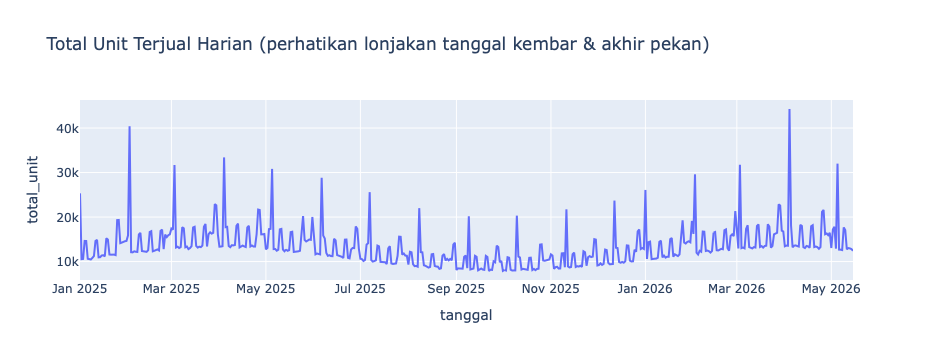

In [4]:
ringkas = (
    df.group_by("tanggal")
    .agg(pl.col("unit_terjual").sum().alias("total_unit"))
    .sort("tanggal")
)
fig = px.line(ringkas, x="tanggal", y="total_unit",
              title="Total Unit Terjual Harian (perhatikan lonjakan tanggal kembar & akhir pekan)")
fig.show()

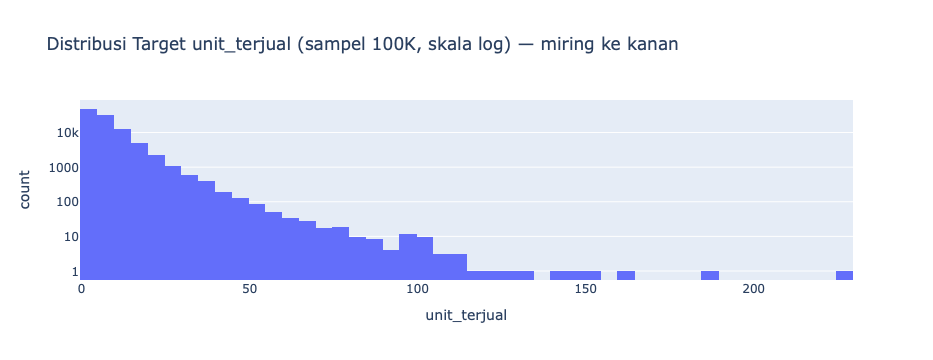

In [5]:
fig = px.histogram(df.sample(100_000, seed=1), x="unit_terjual", nbins=60, log_y=True,
                   title="Distribusi Target unit_terjual (sampel 100K, skala log) — miring ke kanan")
fig.show()

---
## Bagian 4: Feature Engineering dengan Polars (Rust, Multi-thread)

Prinsip penting: **lakukan transformasi berat di Polars/DuckDB**, lalu serahkan matriks yang sudah ringkas ke scikit-learn.

Fitur yang dibuat:
| Jenis | Fitur |
|---|---|
| Kalender | `hari_minggu`, `tanggal_bulan`, `bulan`, `is_weekend`, `is_gajian`, `is_tanggal_kembar` |
| Lag (masa lalu) | `lag_1`, `lag_7` — penjualan 1 dan 7 hari sebelumnya |
| Rolling | `rolling_mean_7`, `rolling_mean_28` — rata-rata bergerak yang **digeser 1 hari** |
| Harga | `rasio_harga` = harga_jual / harga_dasar |

⚠️ **Anti-leakage:** semua fitur lag/rolling memakai `.shift(1)` sehingga **hanya memakai informasi sebelum hari prediksi**.

In [6]:
t0 = time.perf_counter()
df_fitur = (
    df.lazy()
    .sort(["produk_id", "tanggal"])
    .with_columns(
        pl.col("tanggal").dt.weekday().alias("hari_minggu"),
        pl.col("tanggal").dt.day().alias("tanggal_bulan"),
        pl.col("tanggal").dt.month().alias("bulan"),
        (pl.col("tanggal").dt.weekday() >= 6).cast(pl.Int8).alias("is_weekend"),
        (pl.col("tanggal").dt.day() >= 25).cast(pl.Int8).alias("is_gajian"),
        (pl.col("tanggal").dt.day() == pl.col("tanggal").dt.month()).cast(pl.Int8).alias("is_tanggal_kembar"),
        (pl.col("harga_jual") / pl.col("harga_dasar")).alias("rasio_harga"),
        pl.col("unit_terjual").shift(1).over("produk_id").alias("lag_1"),
        pl.col("unit_terjual").shift(7).over("produk_id").alias("lag_7"),
        pl.col("unit_terjual").shift(1).rolling_mean(7).over("produk_id").alias("rolling_mean_7"),
        pl.col("unit_terjual").shift(1).rolling_mean(28).over("produk_id").alias("rolling_mean_28"),
    )
    .drop_nulls(["rolling_mean_28"])     # buang 28 hari pertama tiap produk (belum punya histori)
    .with_columns(pl.col(pl.Float64).cast(pl.Float32))   # downcasting hemat RAM
    .collect()
)
print(f"Feature engineering selesai dalam {time.perf_counter() - t0:.2f} detik")
print(f"Dimensi data fitur: {df_fitur.shape}, memori: {df_fitur.estimated_size('mb'):.1f} MB")
df_fitur.select(["produk_id", "tanggal", "unit_terjual", "lag_1", "lag_7", "rolling_mean_7", "rolling_mean_28"]).head(5)

Feature engineering selesai dalam 0.19 detik
Dimensi data fitur: (944000, 20), memori: 66.2 MB


produk_id,tanggal,unit_terjual,lag_1,lag_7,rolling_mean_7,rolling_mean_28
i32,date,i32,i32,i32,f32,f32
0,2025-01-29,1,2,1,2.0,1.642857
0,2025-01-30,2,1,1,2.0,1.642857
0,2025-01-31,1,2,3,2.142857,1.607143
0,2025-02-01,2,1,2,1.857143,1.571429
0,2025-02-02,12,2,3,1.857143,1.607143


---
## Bagian 5: Time-based Split (Bukan Random Split!)

Data penjualan adalah **deret waktu**. Jika kita memakai `train_test_split` acak, model "mengintip masa depan" (*temporal leakage*) dan skor evaluasi menjadi terlalu optimis.

Strategi yang benar: **latih pada masa lalu, uji pada masa depan.**
- Train: semua tanggal **sebelum** 1 April 2026
- Test : 1 April 2026 – 15 Mei 2026 (45 hari terakhir)

In [7]:
FITUR_NUMERIK = ["harga_dasar", "harga_jual", "diskon_persen", "rasio_harga", "rating_toko",
                 "lag_1", "lag_7", "rolling_mean_7", "rolling_mean_28"]
FITUR_KALENDER = ["hari_minggu", "tanggal_bulan", "bulan", "is_weekend", "is_gajian", "is_tanggal_kembar"]
FITUR_KATEGORI = ["kategori", "wilayah_gudang"]
FITUR = FITUR_NUMERIK + FITUR_KALENDER + FITUR_KATEGORI
TARGET = "unit_terjual"

tanggal_potong = pl.date(2026, 4, 1)
train = df_fitur.filter(pl.col("tanggal") < tanggal_potong)
test = df_fitur.filter(pl.col("tanggal") >= tanggal_potong)

# Konversi Polars -> pandas (zero-copy via Arrow) hanya untuk kolom yang diperlukan
X_train, y_train = train.select(FITUR).to_pandas(), train[TARGET].to_numpy()
X_test, y_test = test.select(FITUR).to_pandas(), test[TARGET].to_numpy()

print(f"Train: {X_train.shape[0]:,} baris | {train['tanggal'].min()} s/d {train['tanggal'].max()}")
print(f"Test : {X_test.shape[0]:,} baris | {test['tanggal'].min()} s/d {test['tanggal'].max()}")

Train: 854,000 baris | 2025-01-29 s/d 2026-03-31
Test : 90,000 baris | 2026-04-01 s/d 2026-05-15


### 5.1 Baseline: Seberapa Bagus "Tebakan Naif"?

Selalu buat **baseline** sebelum model kompleks. Dua baseline umum:
1. `DummyRegressor` — selalu menebak rata-rata.
2. **Naive forecast** — prediksi hari ini = penjualan kemarin (`lag_1`).

Model ML baru layak dipakai jika **jelas mengalahkan** baseline ini.

In [8]:
def evaluasi(nama, y_true, y_pred):
    return {
        "model": nama,
        "MAE": round(mean_absolute_error(y_true, y_pred), 3),
        "RMSE": round(root_mean_squared_error(y_true, y_pred), 3),
        "R2": round(r2_score(y_true, y_pred), 4),
    }

hasil = []
dummy = DummyRegressor(strategy="mean").fit(X_train, y_train)
hasil.append(evaluasi("Baseline: rata-rata", y_test, dummy.predict(X_test)))
hasil.append(evaluasi("Baseline: lag_1 (kemarin)", y_test, X_test["lag_1"]))
pl.DataFrame(hasil)

model,MAE,RMSE,R2
str,f64,f64,f64
"""Baseline: rata-rata""",5.113,8.518,-0.0254
"""Baseline: lag_1 (kemarin)""",5.228,9.043,-0.1554


---
## Bagian 6: Scikit-learn Pipeline + ColumnTransformer

`Pipeline` menggabungkan **preprocessing + model** dalam satu objek:
- `fit()` hanya mempelajari parameter preprocessing (mean, kategori, dst.) dari **data latih** → mencegah *data leakage*.
- Objek yang sama bisa disimpan (`joblib`) dan dipakai di dashboard Streamlit (Pertemuan 10).

In [9]:
preprocess_linear = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), FITUR_NUMERIK + FITUR_KALENDER),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), FITUR_KATEGORI),
])

pipe_sgd = Pipeline([
    ("prep", preprocess_linear),
    ("model", SGDRegressor(
        loss="squared_error", alpha=1e-4,
        max_iter=1000, tol=1e-3,
        early_stopping=True,       # sisihkan 10% data latih sebagai validasi internal
        n_iter_no_change=5,        # berhenti jika skor validasi tidak membaik 5 epoch
        random_state=2026)),
])

t0 = time.perf_counter()
pipe_sgd.fit(X_train, y_train)
waktu_sgd = time.perf_counter() - t0
hasil.append(evaluasi("SGDRegressor (linear)", y_test, pipe_sgd.predict(X_test)) | {"waktu_fit_s": round(waktu_sgd, 2)})
print(f"Waktu training SGD: {waktu_sgd:.2f} detik untuk {len(X_train):,} baris, "
      f"epoch terpakai: {pipe_sgd.named_steps['model'].n_iter_}")
pipe_sgd

Waktu training SGD: 3.53 detik untuk 854,000 baris, epoch terpakai: 6


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](17,)","['harga_dasar','harga_jual','diskon_persen',...,'is_tanggal_kembar', 'kategori','wilayah_gudang']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,17
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This

---
## Bagian 7: Random Forest vs Histogram Gradient Boosting

| | **Random Forest** (Bagging) | **Gradient Boosting** (Boosting) |
|---|---|---|
| Cara kerja | Banyak pohon **independen** dilatih paralel pada sampel bootstrap, hasil dirata-rata | Pohon dilatih **berurutan**, tiap pohon memperbaiki *residual* pohon sebelumnya |
| Kelebihan | Robust, mudah diparalelkan (`n_jobs=-1`) | Akurasi biasanya tertinggi pada data tabular |
| Tantangan big data | Memori besar (pohon dalam × banyak) | Lambat jika split dicari di semua nilai unik |
| Solusi | `max_samples`, `max_depth`, `min_samples_leaf` | **Histogram binning** (`HistGradientBoosting`, LightGBM) |

Model berbasis pohon **tidak butuh scaling** → cukup encode kategori dengan `OrdinalEncoder`.

In [10]:
preprocess_tree = ColumnTransformer([
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), FITUR_KATEGORI),
], remainder="passthrough", verbose_feature_names_out=False)

# --- Random Forest: dilatih pada SAMPEL agar muat memori & waktu wajar ---
pipe_rf = Pipeline([
    ("prep", preprocess_tree),
    ("model", RandomForestRegressor(
        n_estimators=100, max_depth=14, min_samples_leaf=20,
        max_samples=0.3,          # tiap pohon hanya melihat 30% data
        n_jobs=-1, random_state=2026)),
])
idx_sampel = np.random.default_rng(7).choice(len(X_train), size=200_000, replace=False)

t0 = time.perf_counter()
pipe_rf.fit(X_train.iloc[idx_sampel], y_train[idx_sampel])
waktu_rf = time.perf_counter() - t0
hasil.append(evaluasi("RandomForest (sampel 200K)", y_test, pipe_rf.predict(X_test)) | {"waktu_fit_s": round(waktu_rf, 2)})
print(f"Random Forest: {waktu_rf:.1f} detik (200K baris sampel)")

Random Forest: 3.6 detik (200K baris sampel)


In [11]:
# --- HistGradientBoosting: sanggup memakai SELURUH data latih ---
idx_kat = [0, 1]   # setelah ColumnTransformer, kolom kategori berada di posisi awal
pipe_hgb = Pipeline([
    ("prep", preprocess_tree),
    ("model", HistGradientBoostingRegressor(
        loss="poisson",            # cocok untuk target berupa hitungan (count)
        max_iter=300, learning_rate=0.1, max_leaf_nodes=63,
        categorical_features=idx_kat,
        early_stopping=True, validation_fraction=0.1, n_iter_no_change=20,
        random_state=2026)),
])

t0 = time.perf_counter()
pipe_hgb.fit(X_train, y_train)
waktu_hgb = time.perf_counter() - t0
hasil.append(evaluasi("HistGradientBoosting (full)", y_test, pipe_hgb.predict(X_test)) | {"waktu_fit_s": round(waktu_hgb, 2)})
print(f"HistGradientBoosting: {waktu_hgb:.1f} detik ({len(X_train):,} baris), "
      f"iterasi terpakai: {pipe_hgb.named_steps['model'].n_iter_}")

HistGradientBoosting: 34.0 detik (854,000 baris), iterasi terpakai: 235


In [12]:
# --- (Opsional) LightGBM: implementasi histogram boosting industri ---
if LGBM_TERSEDIA:
    pipe_lgb = Pipeline([
        ("prep", preprocess_tree),
        ("model", lgb.LGBMRegressor(objective="poisson", n_estimators=300, learning_rate=0.1,
                                    num_leaves=63, n_jobs=-1, random_state=2026, verbose=-1)),
    ])
    t0 = time.perf_counter()
    pipe_lgb.fit(X_train, y_train)
    waktu_lgb = time.perf_counter() - t0
    hasil.append(evaluasi("LightGBM (full)", y_test, pipe_lgb.predict(X_test)) | {"waktu_fit_s": round(waktu_lgb, 2)})
    print(f"LightGBM: {waktu_lgb:.1f} detik")
else:
    print("LightGBM belum terpasang. Rebuild image Docker (docker compose build) untuk mencobanya.")

LightGBM: 21.5 detik


In [13]:
tabel_hasil = pl.DataFrame(hasil, strict=False).sort("MAE")
tabel_hasil

model,MAE,RMSE,R2,waktu_fit_s
str,f64,f64,f64,f64
"""HistGradientBoosting (full)""",2.743,4.173,0.7539,34.02
"""LightGBM (full)""",2.745,4.109,0.7615,21.48
"""RandomForest (sampel 200K)""",2.825,4.545,0.7081,3.55
"""SGDRegressor (linear)""",3.113,5.201,0.6178,3.53
"""Baseline: rata-rata""",5.113,8.518,-0.0254,null
"""Baseline: lag_1 (kemarin)""",5.228,9.043,-0.1554,null


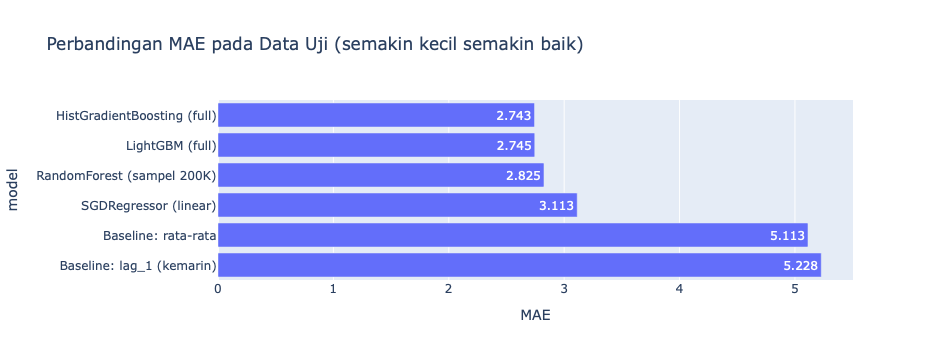

In [14]:
fig = px.bar(tabel_hasil.to_pandas(), x="MAE", y="model", orientation="h", text="MAE",
             title="Perbandingan MAE pada Data Uji (semakin kecil semakin baik)")
fig.update_layout(yaxis={"categoryorder": "total descending"})
fig.show()

---
## Bagian 8: Incremental Learning dengan `partial_fit` (Out-of-Core)

Bagaimana jika data **10× lebih besar** dan tidak muat di RAM? Gunakan estimator yang mendukung `partial_fit`:
`SGDRegressor`, `SGDClassifier`, `MultinomialNB`, `MiniBatchKMeans`, `PassiveAggressive*`.

Data dibaca **per batch** dari Parquet menggunakan `pl.scan_parquet(...).slice()` — hanya satu batch berada di memori pada satu waktu.

⚠️ Scaler juga harus incremental: `StandardScaler.partial_fit()`.

Incremental SGD selesai dalam 0.8 detik, 18 batch, MAE akhir: 3.133


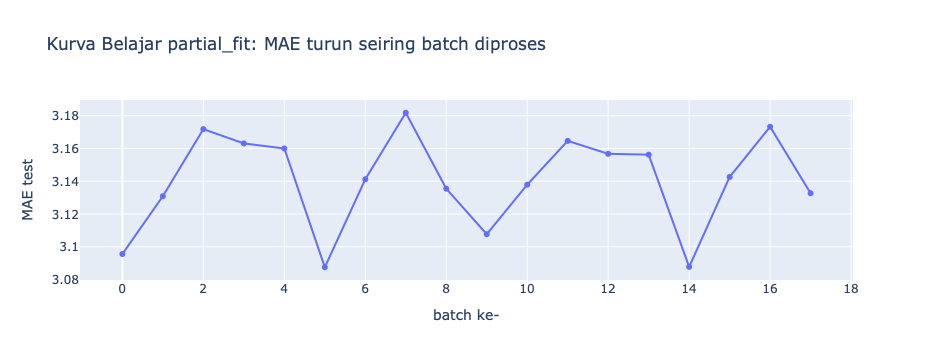

In [15]:
BATCH = 100_000
lf_train = (
    df_fitur.lazy()                       # di dunia nyata: pl.scan_parquet("fitur/*.parquet")
    .filter(pl.col("tanggal") < tanggal_potong)
    .select(FITUR_NUMERIK + FITUR_KALENDER + [TARGET])
)
n_total = lf_train.select(pl.len()).collect().item()

scaler_inc = StandardScaler()
sgd_inc = SGDRegressor(alpha=1e-4, learning_rate="invscaling", eta0=0.01, random_state=2026)

# Pass 1: pelajari statistik scaler secara incremental
for mulai in range(0, n_total, BATCH):
    batch = lf_train.slice(mulai, BATCH).collect()
    scaler_inc.partial_fit(batch.drop(TARGET).to_numpy())

# Pass 2: latih model per batch (2 epoch)
t0 = time.perf_counter()
riwayat_mae = []
X_test_num = scaler_inc.transform(test.select(FITUR_NUMERIK + FITUR_KALENDER).to_numpy())
for epoch in range(2):
    for mulai in range(0, n_total, BATCH):
        batch = lf_train.slice(mulai, BATCH).collect()
        Xb = scaler_inc.transform(batch.drop(TARGET).to_numpy())
        sgd_inc.partial_fit(Xb, batch[TARGET].to_numpy())
        riwayat_mae.append(mean_absolute_error(y_test, sgd_inc.predict(X_test_num)))

print(f"Incremental SGD selesai dalam {time.perf_counter() - t0:.1f} detik, "
      f"{len(riwayat_mae)} batch, MAE akhir: {riwayat_mae[-1]:.3f}")
px.line(y=riwayat_mae, markers=True, labels={"x": "batch ke-", "y": "MAE test"},
        title="Kurva Belajar partial_fit: MAE turun seiring batch diproses").show()

---
## Bagian 9: Evaluasi Lebih Dalam

### 9.1 Interpretasi Metrik Regresi
- **MAE** (*Mean Absolute Error*): rata-rata selisih absolut → "rata-rata meleset sekian unit". Mudah dijelaskan ke manajer.
- **RMSE** (*Root Mean Squared Error*): menghukum kesalahan besar lebih berat → penting jika *stock-out* saat lonjakan sangat mahal.
- **R²**: proporsi variasi target yang dijelaskan model (1 = sempurna, 0 = setara menebak rata-rata).

In [16]:
y_pred_hgb = pipe_hgb.predict(X_test)
eval_df = test.select(["tanggal", "kategori", "is_tanggal_kembar", TARGET]).with_columns(
    pl.Series("prediksi", y_pred_hgb),
).with_columns((pl.col("prediksi") - pl.col(TARGET)).abs().alias("abs_error"))

# Error per segmen — model bagus secara rata-rata belum tentu bagus di semua segmen!
eval_df.group_by("is_tanggal_kembar").agg(
    pl.len().alias("n"),
    pl.col("abs_error").mean().round(3).alias("MAE"),
    pl.col(TARGET).mean().round(2).alias("rata2_aktual"),
)

is_tanggal_kembar,n,MAE,rata2_aktual
i8,u32,f64,f64
0,86000,2.62,7.39
1,4000,5.396,19.07


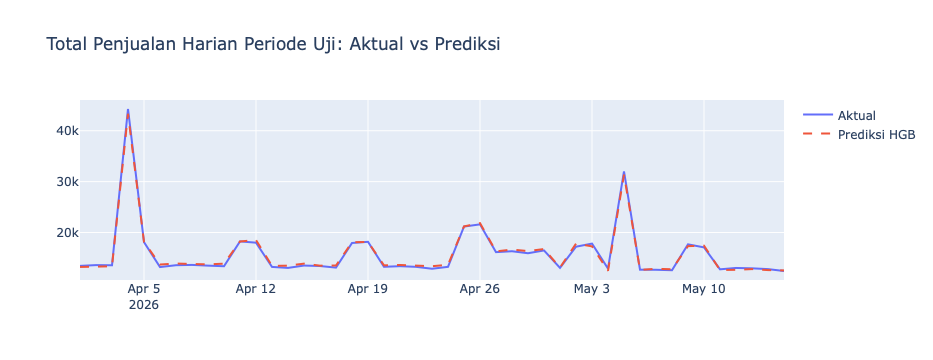

In [17]:
harian = eval_df.group_by("tanggal").agg(pl.col(TARGET).sum().alias("aktual"),
                                         pl.col("prediksi").sum().alias("prediksi")).sort("tanggal")
fig = go.Figure()
fig.add_trace(go.Scatter(x=harian["tanggal"], y=harian["aktual"], name="Aktual"))
fig.add_trace(go.Scatter(x=harian["tanggal"], y=harian["prediksi"], name="Prediksi HGB", line={"dash": "dash"}))
fig.update_layout(title="Total Penjualan Harian Periode Uji: Aktual vs Prediksi")
fig.show()

### 9.2 Cross-Validation untuk Deret Waktu: `TimeSeriesSplit`

K-Fold acak tidak cocok untuk deret waktu. `TimeSeriesSplit` membuat fold berurutan (train selalu sebelum validasi).
Pada data besar, gunakan **k kecil (3–5)** karena setiap fold berarti melatih ulang model.

In [18]:
train_urut = train.sort("tanggal")
X_cv = train_urut.select(FITUR).to_pandas()
y_cv = train_urut[TARGET].to_numpy()

pipe_hgb_cv = Pipeline([("prep", preprocess_tree),
                        ("model", HistGradientBoostingRegressor(loss="poisson", max_iter=100,
                                                                categorical_features=idx_kat, random_state=2026))])
t0 = time.perf_counter()
skor = cross_val_score(pipe_hgb_cv, X_cv, y_cv, cv=TimeSeriesSplit(n_splits=3),
                       scoring="neg_mean_absolute_error", n_jobs=1)
print(f"MAE per fold : {np.round(-skor, 3)}")
print(f"MAE rata-rata: {-skor.mean():.3f} ± {skor.std():.3f}  ({time.perf_counter() - t0:.1f} detik)")

MAE per fold : [2.36  2.057 2.563]
MAE rata-rata: 2.327 ± 0.208  (20.6 detik)


---
## Bagian 10: Feature Importance — Apa yang Mendorong Penjualan?

| Metode | Cara Hitung | Catatan |
|---|---|---|
| **Impurity-based** (`feature_importances_`) | Total penurunan *impurity* (varians/MSE) dari split yang memakai fitur tsb. | Cepat, tetapi **bias** ke fitur kontinu / kardinalitas tinggi, dan dihitung dari data latih |
| **Permutation importance** | Acak nilai satu fitur → ukur seberapa besar skor model memburuk | *Model-agnostic*, dihitung di data uji, lebih jujur — tetapi lebih mahal (pakai sampel) |

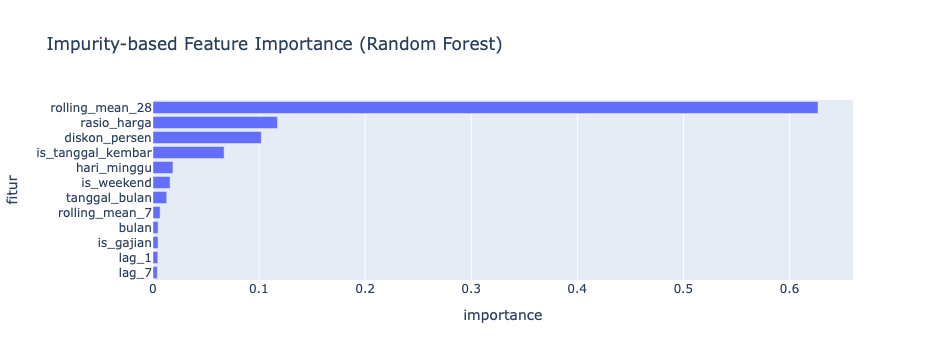

In [19]:
# Impurity-based dari Random Forest
nama_fitur = pipe_rf.named_steps["prep"].get_feature_names_out()
imp_rf = pl.DataFrame({"fitur": nama_fitur,
                       "importance": pipe_rf.named_steps["model"].feature_importances_}).sort("importance", descending=True)

fig = px.bar(imp_rf.head(12).to_pandas(), x="importance", y="fitur", orientation="h",
             title="Impurity-based Feature Importance (Random Forest)")
fig.update_layout(yaxis={"categoryorder": "total ascending"})
fig.show()

Permutation importance selesai dalam 8.0 detik


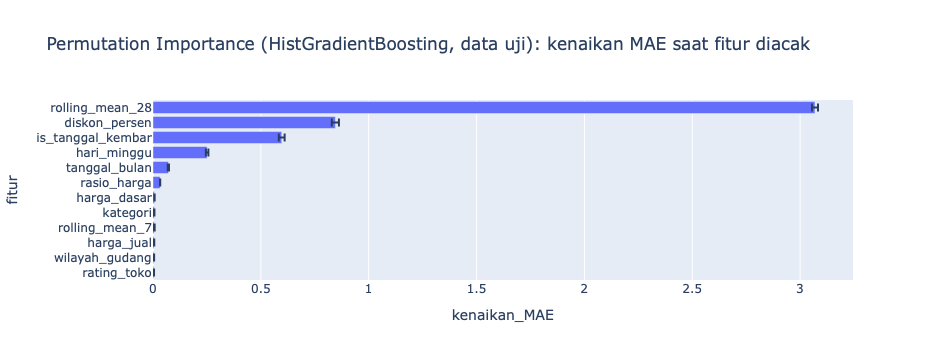

In [20]:
# Permutation importance pada SAMPEL data uji (hemat waktu pada big data)
idx_pi = np.random.default_rng(11).choice(len(X_test), size=20_000, replace=False)
t0 = time.perf_counter()
pi = permutation_importance(pipe_hgb, X_test.iloc[idx_pi], y_test[idx_pi],
                            scoring="neg_mean_absolute_error", n_repeats=5, random_state=2026, n_jobs=-1)
print(f"Permutation importance selesai dalam {time.perf_counter() - t0:.1f} detik")

imp_pi = pl.DataFrame({"fitur": FITUR, "kenaikan_MAE": pi.importances_mean,
                       "std": pi.importances_std}).sort("kenaikan_MAE", descending=True)
fig = px.bar(imp_pi.head(12).to_pandas(), x="kenaikan_MAE", y="fitur", orientation="h", error_x="std",
             title="Permutation Importance (HistGradientBoosting, data uji): kenaikan MAE saat fitur diacak")
fig.update_layout(yaxis={"categoryorder": "total ascending"})
fig.show()

**Diskusi:**
1. Mengapa `rolling_mean_28` sangat dominan, sedangkan `lag_1` hampir tidak berguna? (Petunjuk: variabel tersembunyi `popularitas` produk "terekam" di rata-rata histori panjang, sementara penjualan satu hari sangat *noisy*.)
2. `rasio_harga` dan `diskon_persen` berkorelasi sempurna (`rasio = 1 − diskon`). Bandingkan peringkat keduanya pada impurity-based vs permutation importance. Apa pelajarannya tentang fitur yang saling berkorelasi?
3. Feature importance **bukan** bukti kausalitas — apa risikonya jika manajer langsung menaikkan diskon berdasarkan grafik ini?

---
## Bagian 11: Menyimpan Pipeline untuk Dashboard (Persiapan Pertemuan 10)

Pipeline lengkap (preprocessing + model) disimpan sebagai **satu file** sehingga aplikasi Streamlit cukup memanggil `model.predict(df_baru)`.

In [21]:
import joblib

os.makedirs("models", exist_ok=True)
path_model = "models/pipeline_demand_hgb.joblib"
joblib.dump(pipe_hgb, path_model, compress=3)
print(f"Model tersimpan: {path_model} ({os.path.getsize(path_model) / 1024**2:.2f} MB)")

model_dimuat = joblib.load(path_model)
contoh = X_test.head(3)
print("Prediksi contoh:", np.round(model_dimuat.predict(contoh), 2), "| Aktual:", y_test[:3])

Model tersimpan: models/pipeline_demand_hgb.joblib (0.72 MB)
Prediksi contoh: [4.67 2.37 6.71] | Aktual: [1 3 7]


---
## Bagian 12: Latihan Mandiri Mahasiswa (Hands-on Challenge)

### Tantangan 1: Fitur Baru dari Polars
Tambahkan fitur `rolling_std_7` (standar deviasi bergerak 7 hari, digeser 1 hari) dan `lag_14`. Latih ulang `pipe_hgb`. Apakah MAE membaik?

In [22]:
# TODO: Tulis kode Anda di sini

### Tantangan 2: Uji Kebocoran Data (Leakage Experiment)
Buat fitur **bocor** `rolling_mean_7_bocor` **tanpa** `.shift(1)` (rata-rata 7 hari **termasuk hari ini**). Latih model dan bandingkan MAE di data uji. Jelaskan mengapa skor yang "terlalu bagus" ini tidak dapat dipakai di produksi.

In [23]:
# TODO: Tulis kode Anda di sini

### Tantangan 3: Tuning Ringan pada Sampel
Gunakan `RandomizedSearchCV` dengan `TimeSeriesSplit(n_splits=3)` pada **sampel 200K baris** untuk mencari `learning_rate`, `max_leaf_nodes`, dan `min_samples_leaf` terbaik pada `HistGradientBoostingRegressor`. Laporkan waktu komputasi dan MAE terbaik.

In [24]:
# TODO: Tulis kode Anda di sini

---
## Rangkuman
1. **Diagnosis memori dulu:** data float64 di scikit-learn bisa jauh lebih besar dari Parquet; lakukan *downcasting* dan pilih kolom seperlunya.
2. **Feature engineering di Polars**, modeling di scikit-learn: transformasi berat dikerjakan oleh mesin Rust multi-thread.
3. **Pipeline + ColumnTransformer** mencegah *data leakage* dan membuat model siap di-deploy.
4. **HistGradientBoosting / LightGBM** mampu melatih jutaan baris dalam hitungan detik berkat *histogram binning*; Random Forest lebih cocok dengan sampel.
5. **partial_fit** adalah jalan keluar ketika data tidak muat di RAM.
6. **Time-based split** dan metrik MAE/RMSE per segmen memberikan evaluasi yang jujur.
7. **Permutation importance** pada data uji lebih andal daripada impurity-based importance.

**Tugas 2 Phase 1 (check-in Pertemuan 10):** terima undangan dan buat team repo di GitHub Classroom, isi `data/README.md` dan `docs/architecture.md`. Model `Pipeline` + `joblib` seperti di Bagian 11 dapat (opsional) dipakai sebagai fitur prediksi di dashboard tim.